 Here is the theory summary for the Quaternion Neural Network (QNN) architecture, translating the principles of your complex-valued approach into a 4D hypercomplex space.


Phase 1: Dual-Quaternion Input Encoding

To process spatial and color data without mathematically entangling their distinct geometric properties, the input is mapped into two separate quaternions and concatenated.

Encode the Spatial Coordinate: Map the 2D pixel location (x,y) to a pure quaternion.

qspace

​=0+ix+jy+0k

The real part is strictly 0 to preserve pure 3D spatial geometry. The k component is 0 to explicitly define the spatial domain as a flat 2D plane.

Encode the HSV Color Data: Convert Hue (H), Saturation (S), and Value (V) into Cartesian coordinates (X,Y,Z) using standard trigonometric mapping. Map these to a second quaternion.

qcolor

​=A+iX+jY+kZ

The real part (A) is reserved for the Alpha (opacity) channel. If the dataset lacks an alpha channel, this must be set to 0. The vector parts (i,j,k) map to the X,Y,Z color dimensions.

Concatenate into a Quaternion Vector: Stack the quaternions to form a 2-dimensional quaternion-valued vector. They are not fused into an octonion.

qin

​=[qspace

​


qcolor

​

​]∈H2

Phase 2: QNN Architectural Considerations

Transitioning your custom components (initialization, activation, dropout, and prototype learning) from C to H requires strict adherence to quaternion non-commutativity and 4D variance scaling.


Initialization

Your CVNN splits the Xavier variance equally across the real and imaginary parts. In a QNN, the variance must be distributed across four components to maintain stable signal propagation and gradient flow.

Special Consideration: If the total target variance for a weight tensor is σ2

, the real, i, j, and k components must each be initialized with a variance of σ2

/4. Standard PyTorch initializers will cause exploding/vanishing gradients if applied directly without this scaling.


Activation Functions

Your complex network uses magnitude/phase-based activations (ModReLU and Cardioid). This is the correct structural approach. Applying standard real-valued ReLU independently to the four quaternion components (Split-ReLU) destroys the quaternion's internal directional vector.

Special Consideration: You must implement a Quaternion ModReLU (H-ModReLU). It isolates the quaternion norm (magnitude) from its directional components.

H-ModReLU(q)=ReLU(∣q∣+b)∣q∣


q

​

Here, b is a trainable real-valued bias parameter. This scales the vector without altering its orientation in 4D space, preserving the geometric correlations learned by the Hamilton product.

Quaternion Dropout

Your CVNN applies a unified mask to drop entire complex neurons. This rule must be strictly enforced in the QNN.

Special Consideration: The dropout mask must be generated as a 1D binary tensor and broadcast across all four components of the quaternion neuron. Dropping only the real part or only specific imaginary axes physically fractures the mapped geometry.


Prototype Learning Head

Your CVNN utilizes a Hermitian inner product to calculate cosine similarity against class prototypes. In a QNN, prototype learning is mathematically valid but requires the Quaternion Inner Product.

Special Consideration: Given an output quaternion vector z and a quaternion prototype matrix P, the similarity cannot be a quaternion. It must be collapsed to a real-valued scalar distance. You compute the real part of the quaternion dot product:

Inner Product=Re(zP∗

)

Where P∗

is the quaternion conjugate (negating the i,j,k components). The cosine similarity is then calculated by dividing this inner product by the product of the quaternion norms of z and P, before applying temperature scaling. 

Training QCNN...
Epoch 01 | Train Acc: 0.2328 | Val Acc: 0.3177
Epoch 02 | Train Acc: 0.2939 | Val Acc: 0.3631
Epoch 03 | Train Acc: 0.3212 | Val Acc: 0.3870
Epoch 04 | Train Acc: 0.3459 | Val Acc: 0.4210
Epoch 05 | Train Acc: 0.3718 | Val Acc: 0.4405
Epoch 06 | Train Acc: 0.3873 | Val Acc: 0.4252
Epoch 07 | Train Acc: 0.4018 | Val Acc: 0.4414
Epoch 08 | Train Acc: 0.4172 | Val Acc: 0.4557
Epoch 09 | Train Acc: 0.4262 | Val Acc: 0.4736
Epoch 10 | Train Acc: 0.4372 | Val Acc: 0.4905
Epoch 11 | Train Acc: 0.4530 | Val Acc: 0.5130
Epoch 12 | Train Acc: 0.4738 | Val Acc: 0.5118
Epoch 13 | Train Acc: 0.4969 | Val Acc: 0.5484
Epoch 14 | Train Acc: 0.5278 | Val Acc: 0.5862
Epoch 15 | Train Acc: 0.5698 | Val Acc: 0.6040
Epoch 16 | Train Acc: 0.6146 | Val Acc: 0.6504
Epoch 17 | Train Acc: 0.6544 | Val Acc: 0.6875
Epoch 18 | Train Acc: 0.6829 | Val Acc: 0.7079
Epoch 19 | Train Acc: 0.7081 | Val Acc: 0.7238
Epoch 20 | Train Acc: 0.7326 | Val Acc: 0.7513
Epoch 21 | Train Acc: 0.7527 | Val Acc: 0.7

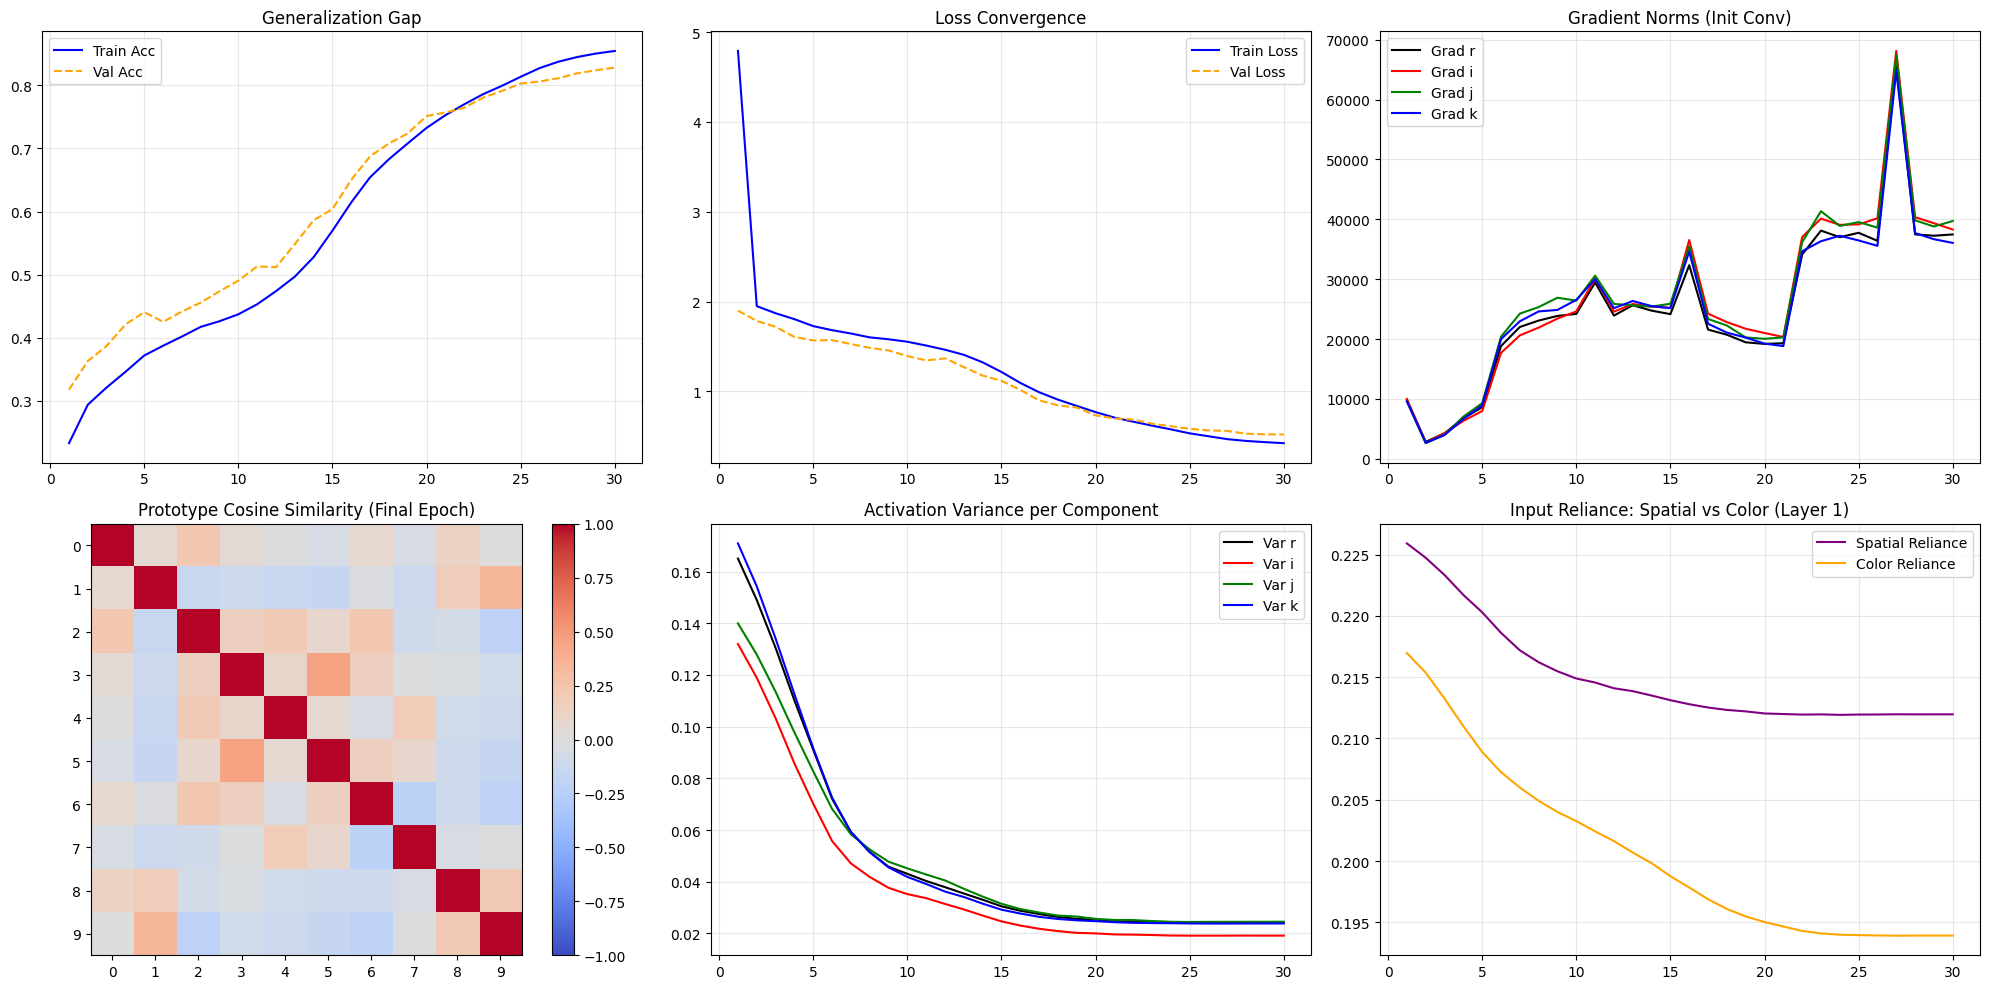

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import math
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# GLOBAL HYPERPARAMETERS
# ==========================================
EPOCHS = 30
DROPOUT_P = 0.2               # Required for high-capacity generalization
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
FILTERS = [32, 64, 128, 256]  # Expanded capacity
METRIC = 'euclidean'          # Options: 'cosine', 'euclidean'
DATA_AUGMENTATION = True      # Toggles spatial geometric noise
# ==========================================

# --- Training Data Pipeline ---
if DATA_AUGMENTATION:
    # Applies spatial perturbation (4px padded random crop and random horizontal flip).
    # Forces the hypercomplex kernels to learn scale- and translation-invariant 
    # spatial-color features rather than memorizing exact pixel alignments.
    transform_train = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])
else:
    # Deterministic pipeline: converts raw images directly to scaled tensors 
    # without introducing geometric spatial noise during training.
    transform_train = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
    ])

transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# --- 1. Quaternion Layers (Block Matrix Optimized) ---
class QuaternionConv2d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0):
        super().__init__()
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.stride = stride
        self.padding = padding
        
        self.weight_r = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.weight_i = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.weight_j = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.weight_k = nn.Parameter(torch.empty(out_channels, in_channels, kernel_size, kernel_size))
        self.bias = nn.Parameter(torch.empty(out_channels * 4))
        
        self.reset_parameters()

    def reset_parameters(self):
        n = self.in_channels * self.weight_r.size(2) * self.weight_r.size(3)
        std = math.sqrt(1.0 / n) / 2.0 
        with torch.no_grad():
            for w in [self.weight_r, self.weight_i, self.weight_j, self.weight_k]:
                nn.init.normal_(w, 0, std)
            nn.init.zeros_(self.bias)

    def forward(self, x):
        # Construct the Hamilton block matrix dynamically
        row1 = torch.cat([self.weight_r, -self.weight_i, -self.weight_j, -self.weight_k], dim=1)
        row2 = torch.cat([self.weight_i, self.weight_r, -self.weight_k, self.weight_j], dim=1)
        row3 = torch.cat([self.weight_j, self.weight_k, self.weight_r, -self.weight_i], dim=1)
        row4 = torch.cat([self.weight_k, -self.weight_j, self.weight_i, self.weight_r], dim=1)
        
        # W_full shape: [out_channels * 4, in_channels * 4, kernel_size, kernel_size]
        W_full = torch.cat([row1, row2, row3, row4], dim=0)
        
        # Execute as a single cuDNN optimized convolution
        return F.conv2d(x, W_full, bias=self.bias, stride=self.stride, padding=self.padding)

class QuaternionLinear(nn.Module):
    def __init__(self, in_features, out_features):
        super().__init__()
        self.weight_r = nn.Parameter(torch.empty(out_features, in_features))
        self.weight_i = nn.Parameter(torch.empty(out_features, in_features))
        self.weight_j = nn.Parameter(torch.empty(out_features, in_features))
        self.weight_k = nn.Parameter(torch.empty(out_features, in_features))
        self.bias = nn.Parameter(torch.empty(out_features * 4))
        
        std = math.sqrt(1.0 / (in_features + out_features)) / 2.0 
        with torch.no_grad():
            for w in [self.weight_r, self.weight_i, self.weight_j, self.weight_k]:
                nn.init.normal_(w, 0, std)
            nn.init.zeros_(self.bias)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        row1 = torch.cat([self.weight_r, -self.weight_i, -self.weight_j, -self.weight_k], dim=1)
        row2 = torch.cat([self.weight_i, self.weight_r, -self.weight_k, self.weight_j], dim=1)
        row3 = torch.cat([self.weight_j, self.weight_k, self.weight_r, -self.weight_i], dim=1)
        row4 = torch.cat([self.weight_k, -self.weight_j, self.weight_i, self.weight_r], dim=1)
        
        W_full = torch.cat([row1, row2, row3, row4], dim=0)
        
        return F.linear(x, W_full, bias=self.bias)

# --- 2. Regularization, Activations & Blocks ---
class HModReLU(nn.Module):
    def __init__(self, features):
        super().__init__()
        self.b = nn.Parameter(torch.full((features,), 0.1))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        r, i, j, k = torch.chunk(x, 4, dim=1)
        mag = torch.sqrt(r**2 + i**2 + j**2 + k**2 + 1e-7)
        b_view = self.b.view(1, -1, *([1]*(x.dim()-2)))
        
        mag_activated = F.relu(mag + b_view)
        scale = mag_activated / (mag + 1e-7)
        return x * scale.repeat(1, 4, *([1]*(x.dim()-2)))

class QuaternionDropout(nn.Module):
    def __init__(self, p=DROPOUT_P):
        super().__init__()
        self.p = p

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.p == 0.0:
            return x
        mask_shape = [x.size(0), x.size(1) // 4] + [1] * (x.dim() - 2)
        mask = F.dropout(torch.ones(mask_shape, device=x.device), p=self.p, training=True)
        return x * mask.repeat(1, 4, *([1]*(x.dim()-2)))

class QuaternionResBlock(nn.Module):
    """Residual block for hypercomplex convolutions."""
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = QuaternionConv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1)
        self.act1 = HModReLU(out_channels)
        self.conv2 = QuaternionConv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1)
        self.act2 = HModReLU(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = QuaternionConv2d(in_channels, out_channels, kernel_size=1, stride=stride, padding=0)

    def forward(self, x):
        out = self.act1(self.conv1(x))
        out = self.conv2(out)
        out += self.shortcut(x)
        return self.act2(out)

# --- 3. Encoding & Prototype Heads ---
class QInputEncoder(nn.Module):
    def __init__(self, size=32):
        super().__init__()
        coords = torch.linspace(-1, 1, steps=size)
        grid_y, grid_x = torch.meshgrid(coords, coords, indexing='ij')
        self.register_buffer('grid_x', grid_x.unsqueeze(0).unsqueeze(0))
        self.register_buffer('grid_y', grid_y.unsqueeze(0).unsqueeze(0))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        batch_size = x.size(0)
        zeros = torch.zeros(batch_size, 1, x.size(2), x.size(3), device=x.device)
        gx = self.grid_x.expand(batch_size, -1, -1, -1)
        gy = self.grid_y.expand(batch_size, -1, -1, -1)
        
        out = torch.cat([zeros, zeros,                  # r
                         gx, x[:, 0:1, :, :],           # i
                         gy, x[:, 1:2, :, :],           # j
                         zeros, x[:, 2:3, :, :]], dim=1) # k
        return out

class PrototypeHead(nn.Module):
    def __init__(self, in_features, num_classes=10, metric=METRIC):
        super().__init__()
        self.metric = metric
        self.prototypes = nn.Parameter(torch.empty(num_classes, in_features * 4))
        self.temperature = nn.Parameter(torch.tensor(10.0 if metric == 'cosine' else 1.0))
        
        std = math.sqrt(1.0 / in_features) / 2.0
        nn.init.normal_(self.prototypes, 0, std)

    def forward(self, x):
        if self.metric == 'cosine':
            inner_product = F.linear(x, self.prototypes)
            x_norm = torch.linalg.norm(x, dim=1, keepdim=True)
            p_norm = torch.linalg.norm(self.prototypes, dim=1).unsqueeze(0)
            sim = inner_product / torch.clamp(x_norm * p_norm, min=1e-5)
            return sim * self.temperature
        elif self.metric == 'euclidean':
            x_sq = torch.sum(x**2, dim=1, keepdim=True)
            p_sq = torch.sum(self.prototypes**2, dim=1).unsqueeze(0)
            cross = F.linear(x, self.prototypes)
            dist_sq = x_sq + p_sq - 2 * cross
            return -self.temperature * dist_sq

# --- 4. Dynamic Network ---
class QCNN(nn.Module):
    def __init__(self, filters=FILTERS):
        super().__init__()
        self.encoder = QInputEncoder(size=32)
        
        self.init_conv = QuaternionConv2d(2, filters[0], kernel_size=3, padding=1)
        self.init_act = HModReLU(filters[0])
        
        layers = []
        in_c = filters[0]
        
        for out_c in filters[1:]:
            layers.append(QuaternionResBlock(in_c, out_c, stride=2))
            in_c = out_c
            
        self.res_blocks = nn.Sequential(*layers)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        
        self.fc1 = QuaternionLinear(in_c, 128)
        self.act_fc = HModReLU(128)
        self.dropout = QuaternionDropout(p=DROPOUT_P)
        self.head = PrototypeHead(128, num_classes=10)

    def forward(self, x: torch.Tensor, capture_activations=False):
        z = self.encoder(x)
        out_conv = self.init_act(self.init_conv(z))
        
        if capture_activations:
            z1 = out_conv
            
        out_conv = self.res_blocks(out_conv)
        out_conv = self.global_pool(out_conv)
        
        flat = out_conv.view(out_conv.size(0), -1)
        z2 = self.dropout(self.act_fc(self.fc1(flat)))
        out = self.head(z2)
        
        if capture_activations:
            return out, z1
        return out

# --- 5. Training Engine ---
def train_qnn(model, file_name, epochs=EPOCHS):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    train_loader = DataLoader(datasets.CIFAR10('./data', train=True, download=True, transform=transform_train), 
                              batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
    test_loader = DataLoader(datasets.CIFAR10('./data', train=False, transform=transform_test), 
                             batch_size=1000, shuffle=False, num_workers=4, pin_memory=True)

    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss()
    
    scaler = torch.amp.GradScaler('cuda')

    history = {
        'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [],
        'grad_r': [], 'grad_i': [], 'grad_j': [], 'grad_k': [],
        'prototype_sim_matrix': None,
        'var_r': [], 'var_i': [], 'var_j': [], 'var_k': [],
        'weight_norm_spatial': [], 'weight_norm_color': []
    }

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct_train, total_train = 0.0, 0, 0
        g_r, g_i, g_j, g_k = 0.0, 0.0, 0.0, 0.0
        
        for data, target in train_loader:
            data, target = data.to(device), target.to(device)
            optimizer.zero_grad()
            
            with torch.amp.autocast('cuda'):
                output = model(data)
                loss = criterion(output, target)
                
            scaler.scale(loss).backward()
            
            if model.init_conv.weight_r.grad is not None:
                g_r += model.init_conv.weight_r.grad.norm().item()
                g_i += model.init_conv.weight_i.grad.norm().item()
                g_j += model.init_conv.weight_j.grad.norm().item()
                g_k += model.init_conv.weight_k.grad.norm().item()
                
            scaler.step(optimizer)
            scaler.update()
            
            total_loss += loss.item() * data.size(0)
            pred = output.argmax(dim=1, keepdim=True)
            correct_train += pred.eq(target.view_as(pred)).sum().item()
            total_train += data.size(0)

        history['grad_r'].append(g_r / len(train_loader))
        history['grad_i'].append(g_i / len(train_loader))
        history['grad_j'].append(g_j / len(train_loader))
        history['grad_k'].append(g_k / len(train_loader))

        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        
        with torch.no_grad():
            for i, (data, target) in enumerate(test_loader):
                data, target = data.to(device), target.to(device)
                with torch.amp.autocast('cuda'):
                    output, z1 = model(data, capture_activations=True)
                    val_loss += criterion(output, target).item() * data.size(0)
                
                pred = output.argmax(dim=1, keepdim=True)
                correct_val += pred.eq(target.view_as(pred)).sum().item()
                total_val += data.size(0)
                
                if i == 0:
                    r, i_comp, j_comp, k_comp = torch.chunk(z1, 4, dim=1)
                    history['var_r'].append(torch.var(r).item())
                    history['var_i'].append(torch.var(i_comp).item())
                    history['var_j'].append(torch.var(j_comp).item())
                    history['var_k'].append(torch.var(k_comp).item())

            p = model.head.prototypes
            p_norm = torch.linalg.norm(p, dim=1, keepdim=True)
            p_normalized = p / torch.clamp(p_norm, min=1e-5)
            history['prototype_sim_matrix'] = torch.matmul(p_normalized, p_normalized.T).cpu().numpy()

            w_r, w_i, w_j, w_k = model.init_conv.weight_r, model.init_conv.weight_i, model.init_conv.weight_j, model.init_conv.weight_k
            w_mag = torch.sqrt(w_r**2 + w_i**2 + w_j**2 + w_k**2)
            history['weight_norm_spatial'].append(w_mag[:, 0].mean().item())
            history['weight_norm_color'].append(w_mag[:, 1].mean().item())

        history['train_loss'].append(total_loss / total_train)
        history['val_loss'].append(val_loss / total_val)
        history['train_acc'].append(correct_train / total_train)
        history['val_acc'].append(correct_val / total_val)

        scheduler.step()
        print(f"Epoch {epoch:02d} | Train Acc: {history['train_acc'][-1]:.4f} | Val Acc: {history['val_acc'][-1]:.4f}")

    torch.save(history, file_name)
    print(f"Saved {file_name}")

# --- 6. Static Plotting Dashboard ---
def plot_dashboard(file_name='qcnn_telemetry.pt'):
    hist = torch.load(file_name, weights_only=False)
    epochs = len(hist['train_loss'])
    
    fig, axes = plt.subplots(2, 3, figsize=(20, 10))
    
    # 1. Accuracies
    ax = axes[0, 0]
    ax.plot(range(1, epochs + 1), hist['train_acc'], label='Train Acc', color='blue')
    ax.plot(range(1, epochs + 1), hist['val_acc'], label='Val Acc', color='orange', linestyle='--')
    ax.set_title("Generalization Gap")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 2. Losses
    ax = axes[0, 1]
    ax.plot(range(1, epochs + 1), hist['train_loss'], label='Train Loss', color='blue')
    ax.plot(range(1, epochs + 1), hist['val_loss'], label='Val Loss', color='orange', linestyle='--')
    ax.set_title("Loss Convergence")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3. Gradients
    ax = axes[0, 2]
    ax.plot(range(1, epochs + 1), hist['grad_r'], label='Grad r', color='black')
    ax.plot(range(1, epochs + 1), hist['grad_i'], label='Grad i', color='red')
    ax.plot(range(1, epochs + 1), hist['grad_j'], label='Grad j', color='green')
    ax.plot(range(1, epochs + 1), hist['grad_k'], label='Grad k', color='blue')
    ax.set_title("Gradient Norms (Init Conv)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 4. Final Prototype Similarity
    ax = axes[1, 0]
    cax = ax.imshow(hist['prototype_sim_matrix'], cmap='coolwarm', vmin=-1, vmax=1)
    fig.colorbar(cax, ax=ax)
    ax.set_title(f"Prototype Cosine Similarity (Final Epoch)")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))
    
    # 5. Variances
    ax = axes[1, 1]
    ax.plot(range(1, epochs + 1), hist['var_r'], label='Var r', color='black')
    ax.plot(range(1, epochs + 1), hist['var_i'], label='Var i', color='red')
    ax.plot(range(1, epochs + 1), hist['var_j'], label='Var j', color='green')
    ax.plot(range(1, epochs + 1), hist['var_k'], label='Var k', color='blue')
    ax.set_title("Activation Variance per Component")
    ax.legend()
    ax.grid(True, alpha=0.3)
    
    # 6. Weight Reliance
    ax = axes[1, 2]
    ax.plot(range(1, epochs + 1), hist['weight_norm_spatial'], label='Spatial Reliance', color='purple')
    ax.plot(range(1, epochs + 1), hist['weight_norm_color'], label='Color Reliance', color='orange')
    ax.set_title("Input Reliance: Spatial vs Color (Layer 1)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

if __name__ == "__main__":
    print("Training QCNN...")
    model = QCNN(filters=FILTERS)
    train_qnn(model, 'qcnn_telemetry.pt')
    plot_dashboard('qcnn_telemetry.pt')